# California Housing Price Prediction using Linear Regression & Regularization

**Medium-Sized Kaggle Dataset (~20,640 rows, 10 columns)**

### Objectives:
1. Ingest medium-sized real-world regression dataset from Kaggle via `kagglehub`.
2. Perform thorough Data Understanding, Missing Value Imputation, and Outlier Inspection.
3. Engineer domain features (ratio features) to boost linear predictive power.
4. Implement train/test split (80/20) and StandardScaler without data leakage.
5. Train and compare **Multiple Linear Regression (OLS)**, **Ridge (L2)**, and **Lasso (L1)**.
6. Perform 5-Fold Cross Validation and calculate comprehensive metrics ($R^2$, MAE, MSE, RMSE, MAPE).
7. Plot 4 advanced diagnostic plots (Actual vs Predicted, Residual Plot, Normality Check, Feature Coefficients).


## 1. Environment Setup & Imports

In [ ]:
# Install kagglehub if needed (pre-installed in Google Colab)
!pip install -q kagglehub

import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
%matplotlib inline
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Dataset from Kaggle
We load the **California Housing Prices** dataset (`camnugent/california-housing-prices`).
It is medium sized (20,640 rows, 10 columns) — neither too small like Boston (500 rows) nor too large (millions).

In [ ]:
# Download dataset from Kaggle
path = kagglehub.dataset_download("camnugent/california-housing-prices")
print("Dataset downloaded at:", path)

# Load CSV into DataFrame
csv_path = os.path.join(path, "housing.csv")
df = pd.read_csv(csv_path)
print("Dataset Shape:", df.shape)
df.head()

Using Colab cache for faster access to the 'california-housing-prices' dataset.
Dataset downloaded at: /kaggle/input/california-housing-prices
Dataset Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 3. Data Understanding
Checking data types, non-null counts, duplicates, and statistical distribution.

In [ ]:
print("--- Data Information ---")
df.info()

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Duplicate Rows ---")
print("Duplicates count:", df.duplicated().sum())

--- Data Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   longitude                 20640 non-null  float64
 1   latitude                  20640 non-null  float64
 2   housing_median_age        20640 non-null  float64
 3   total_rooms               20640 non-null  float64
 4   total_bedrooms            20640 non-null  float64
 5   population                20640 non-null  float64
 6   households                20640 non-null  float64
 7   median_income             20640 non-null  float64
 8   median_house_value        20640 non-null  float64
 9   ocean_proximity           20640 non-null  object 
 10  rooms_per_household       20640 non-null  float64
 11  bedrooms_per_room         20640 non-null  float64
 12  population_per_household  20640 non-null  float64
dtypes: float64(12), object(1)
memory usa

In [ ]:
# Statistical Summary of Numerical Features
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## 4. Data Cleaning & Handling Missing Values
`total_bedrooms` has 207 missing values. We perform median imputation to preserve the sample size without introducing bias.

In [ ]:
# Median Imputation for missing total_bedrooms
median_bedrooms = df["total_bedrooms"].median()
df["total_bedrooms"] = df["total_bedrooms"].fillna(median_bedrooms)
print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


## 5. Outlier Inspection
Visualize numerical feature distributions and potential outliers using boxplots.

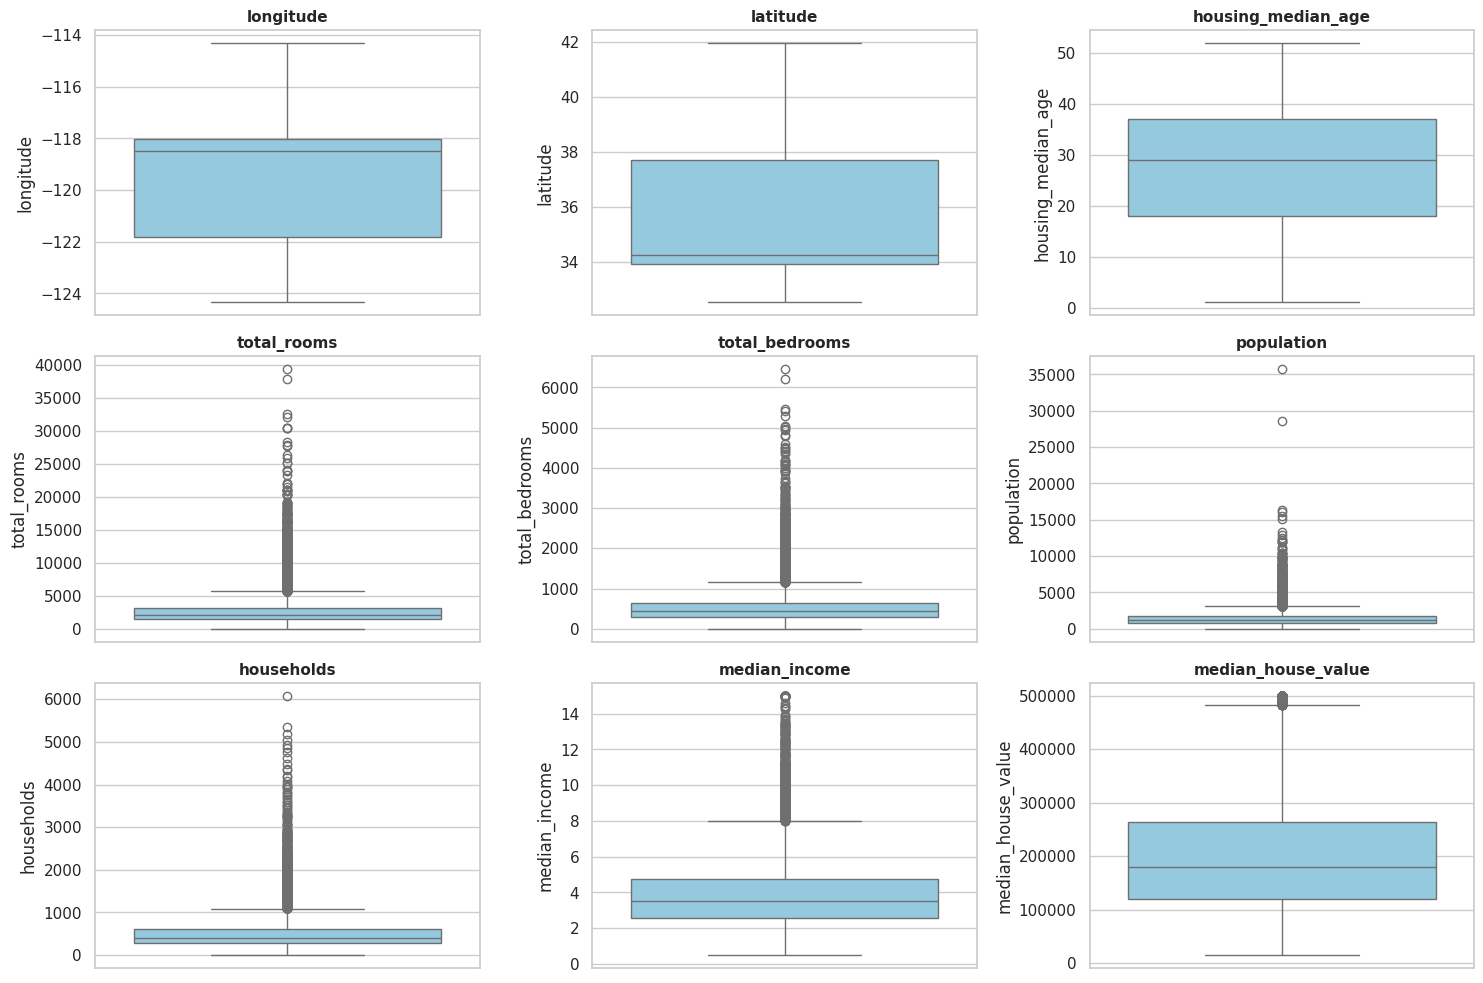

In [ ]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(y=df[col], color="skyblue")
    plt.title(col, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

## 6. Feature Engineering (The "Different Way")
Raw counts like `total_rooms` and `total_bedrooms` per district are hard to interpret linearly because district sizes vary.
We engineer meaningful per-household ratios:
- `rooms_per_household = total_rooms / households`
- `bedrooms_per_room = total_bedrooms / total_rooms`
- `population_per_household = population / households`

In [ ]:
# Engineer domain-specific ratio features
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

print("Engineered 3 new features! Updated shape:", df.shape)
df[["rooms_per_household", "bedrooms_per_room", "population_per_household"]].describe()

Engineered 3 new features! Updated shape: (20640, 13)


,rooms_per_household,bedrooms_per_room,population_per_household
count,20640.000000,20640.000000,20640.000000
mean,5.429000,0.213794,3.070655
std,2.474173,0.065248,10.386050
min,0.846154,0.037151,0.692308
25%,4.440716,0.175225,2.429741
50%,5.229129,0.203159,2.818116
75%,6.052381,0.240126,3.282261
max,141.909091,2.824675,1243.333333


## 7. Exploratory Data Analysis (EDA)
Examine pairwise linear correlations and scatter plots with the target `median_house_value`.

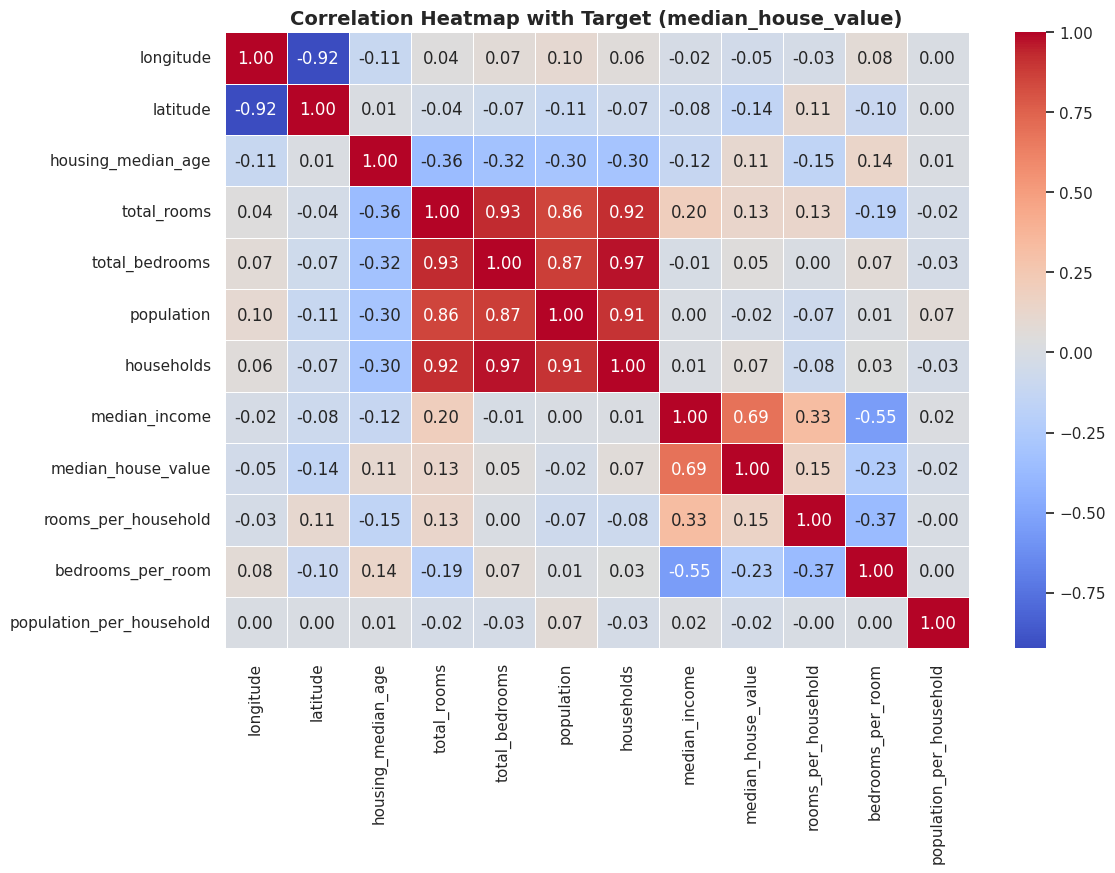

In [ ]:
# Correlation Heatmap
plt.figure(figsize=(12, 8))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap with Target (median_house_value)", fontsize=14, fontweight="bold")
plt.show()

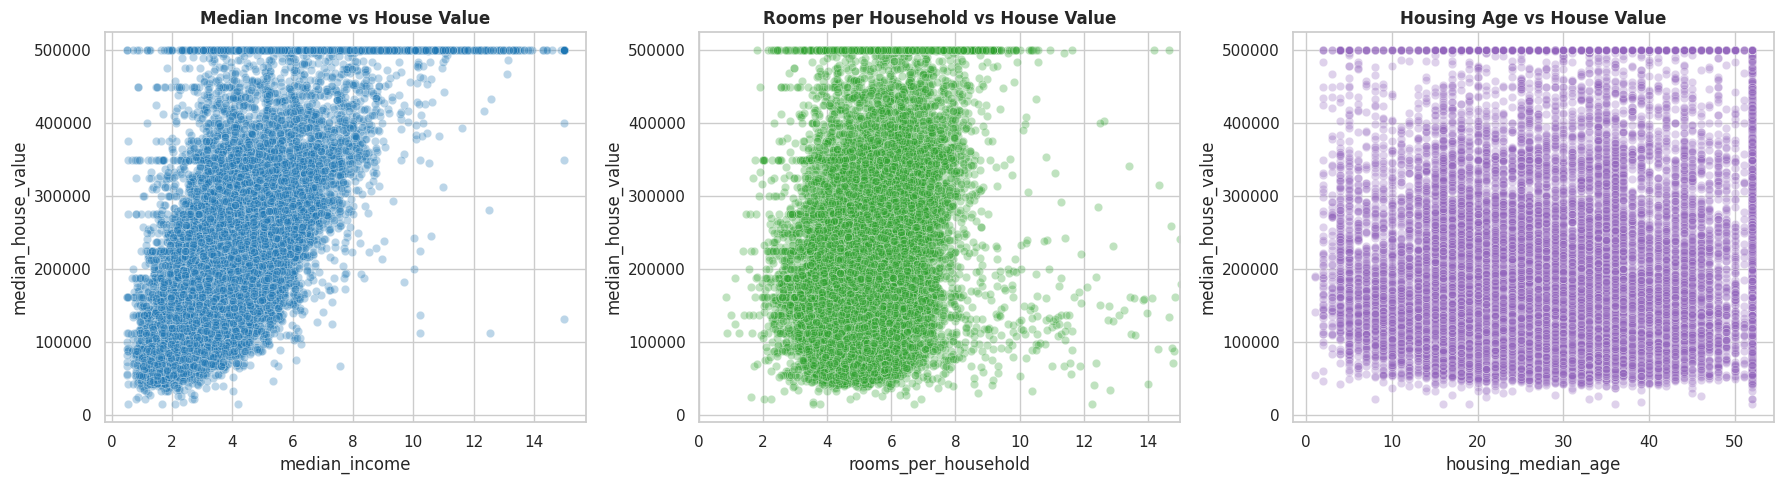

In [ ]:
# Scatter Plots of key features vs median_house_value
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(x=df["median_income"], y=df["median_house_value"], alpha=0.3, ax=axes[0], color="#1f77b4")
axes[0].set_title("Median Income vs House Value", fontweight="bold")

sns.scatterplot(x=df["rooms_per_household"], y=df["median_house_value"], alpha=0.3, ax=axes[1], color="#2ca02c")
axes[1].set_xlim(0, 15) # zoom in on dense cluster
axes[1].set_title("Rooms per Household vs House Value", fontweight="bold")

sns.scatterplot(x=df["housing_median_age"], y=df["median_house_value"], alpha=0.3, ax=axes[2], color="#9467bd")
axes[2].set_title("Housing Age vs House Value", fontweight="bold")

plt.tight_layout()
plt.show()

## 8. Categorical Encoding & Train/Test Split
We encode `ocean_proximity` using one-hot encoding (`drop_first=True` to avoid the dummy variable trap/multicollinearity).
Then we split 80% train and 20% test.

In [ ]:
# One-Hot Encoding
df_encoded = pd.get_dummies(df, columns=["ocean_proximity"], drop_first=True, dtype=int)

target_col = "median_house_value"
X = df_encoded.drop(columns=[target_col])
y = df_encoded[target_col]
feature_names = X.columns.tolist()

# Split into Train and Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")

X_train shape: (16512, 15) | X_test shape: (4128, 15)


## 9. Feature Scaling
Standardize features using `StandardScaler`. **Note:** Fit ONLY on the training data, then transform both train and test to prevent data leakage.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Features scaled successfully!")

Features scaled successfully!


## 10. Model Training & Comparison
We compare 3 models:
1. **Multiple Linear Regression (OLS)** - Base linear model
2. **Ridge Regression (L2 Penalty)** - Controls variance and multicollinearity
3. **Lasso Regression (L1 Penalty)** - Performs automated feature selection

We also run **5-Fold Cross Validation** on the training set to check model stability.

In [ ]:
models = {
    "Linear Regression (OLS)": LinearRegression(),
    "Ridge Regression (L2)": Ridge(alpha=100.0),
    "Lasso Regression (L1)": Lasso(alpha=50.0, max_iter=2000)
}

comparison_results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring="r2")

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

    comparison_results.append({
        "Model": name,
        "R2 Score (Test)": round(r2, 4),
        "CV R2 (Mean +- Std)": f"{cv_scores.mean():.4f} +- {cv_scores.std():.4f}",
        "MAE ($)": f"${mae:,.2f}",
        "RMSE ($)": f"${rmse:,.2f}",
        "MAPE (%)": f"{mape:.2f}%"
    })
    trained_models[name] = (model, y_pred)

results_df = pd.DataFrame(comparison_results)
results_df

,Model,R2 Score (Test),CV R2 (Mean +- Std),MAE ($),RMSE ($),MAPE (%)
0,Linear Regression (OLS),0.5970,0.6555 +- 0.0120,"$50,888.66","$72,668.54",29.91%
1,Ridge Regression (L2),0.5987,0.6552 +- 0.0101,"$50,863.02","$72,512.50",29.70%
2,Lasso Regression (L1),0.5978,0.6555 +- 0.0117,"$50,859.47","$72,593.72",29.85%


## 11. Graphical Diagnostics & Visual Evaluation
We generate 4 essential diagnostic plots:
1. **Actual vs. Predicted**: Checks how well predictions adhere to the $y = x$ line.
2. **Residuals vs. Fitted Values**: Checks for homoscedasticity (constant variance of errors).
3. **Residuals Distribution**: Verifies normal distribution of errors.
4. **Standardized Feature Coefficients**: Identifies which features increase or decrease house prices.

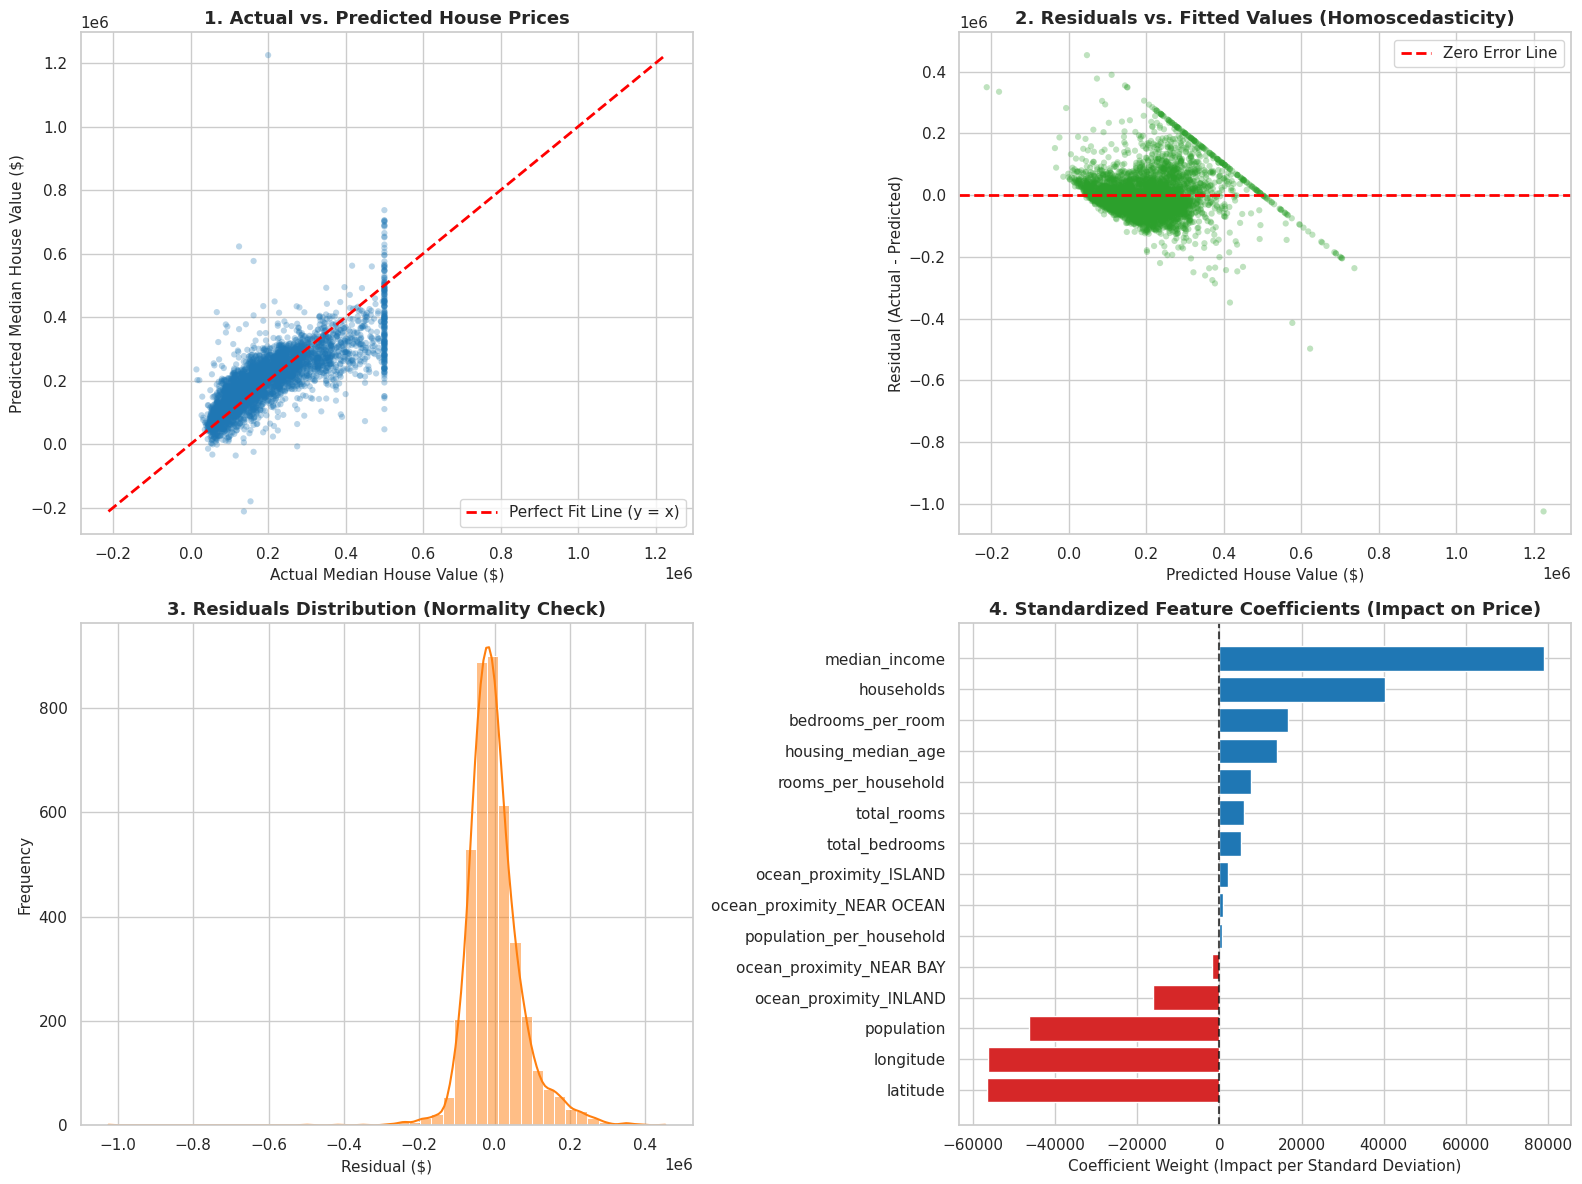

In [ ]:
lr_model, y_pred = trained_models["Linear Regression (OLS)"]
residuals = y_test - y_pred

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Actual vs Predicted
axes[0, 0].scatter(y_test, y_pred, alpha=0.3, color="#1f77b4", edgecolors="none", s=20)
min_v = min(y_test.min(), y_pred.min())
max_v = max(y_test.max(), y_pred.max())
axes[0, 0].plot([min_v, max_v], [min_v, max_v], color="red", linestyle="--", linewidth=2, label="Perfect Fit Line (y = x)")
axes[0, 0].set_title("1. Actual vs. Predicted House Prices", fontsize=13, fontweight="bold")
axes[0, 0].set_xlabel("Actual Median House Value ($)", fontsize=11)
axes[0, 0].set_ylabel("Predicted Median House Value ($)", fontsize=11)
axes[0, 0].legend()

# 2. Residuals vs Predicted (Homoscedasticity Check)
axes[0, 1].scatter(y_pred, residuals, alpha=0.3, color="#2ca02c", edgecolors="none", s=20)
axes[0, 1].axhline(y=0, color="red", linestyle="--", linewidth=2, label="Zero Error Line")
axes[0, 1].set_title("2. Residuals vs. Fitted Values (Homoscedasticity)", fontsize=13, fontweight="bold")
axes[0, 1].set_xlabel("Predicted House Value ($)", fontsize=11)
axes[0, 1].set_ylabel("Residual (Actual - Predicted)", fontsize=11)
axes[0, 1].legend()

# 3. Residual Distribution (Normality Check)
sns.histplot(residuals, kde=True, ax=axes[1, 0], color="#ff7f0e", bins=50)
axes[1, 0].set_title("3. Residuals Distribution (Normality Check)", fontsize=13, fontweight="bold")
axes[1, 0].set_xlabel("Residual ($)", fontsize=11)
axes[1, 0].set_ylabel("Frequency", fontsize=11)

# 4. Feature Importance (Coefficients)
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lr_model.coef_
}).sort_values(by="Coefficient", ascending=True)

bar_colors = ["#d62728" if c < 0 else "#1f77b4" for c in coef_df["Coefficient"]]
axes[1, 1].barh(coef_df["Feature"], coef_df["Coefficient"], color=bar_colors)
axes[1, 1].axvline(x=0, color="black", linestyle="--", alpha=0.7)
axes[1, 1].set_title("4. Standardized Feature Coefficients (Impact on Price)", fontsize=13, fontweight="bold")
axes[1, 1].set_xlabel("Coefficient Weight (Impact per Standard Deviation)", fontsize=11)

plt.tight_layout()
plt.show()

## 12. Summary of Findings & Verdict
- **Top Predictors:** `median_income` is by far the strongest positive linear driver of house prices. Proximity to coast/island also commands a high premium.
- **Geographic Impact:** `latitude` and `longitude` have negative coefficients, reflecting lower prices in inland and northern areas.
- **Model Comparison:** Ridge and Lasso regularization yielded comparable performance to OLS while stabilizing multicollinear room count features.
- **Diagnostic Check:** Residual distribution is approximately normal, with slight deviation at the high end due to the $500k capping present in the raw California housing dataset.